# Well-balancing: a radiative hydrostatic envelope stays at rest

A grey scattering envelope in hydrostatic and radiative equilibrium (`decks/rhse_sp.athinput`,
2-D spherical polar, t = 10; `decks/rhse_cs.athinput`, cubed sphere, t = 2.5) must stay at rest.
Criterion: the largest $|v|/c_s$ over the run $\le 10^{-8}$.

The last part reruns `rhse_sp` with an extra binary dump at t = 0 and at the end to show the
radial profiles (the same run as the test; a dump does not change it).

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('.'))   # this notebook's folder: tests/vet_clean/notebooks
import nbutil as nb                        # nb.suite, nb.verdict, nb.m1t (readers), nb.rt (run_tests)

# the athena binary (a CPU build, default the one tests/vet_clean/run_tests.sh builds)
EXE = os.path.abspath(os.environ.get('ATHENA_EXE', '../../../build_m1test/src/athena'))
# where the runs go; a test whose run is already there is only loaded, not rerun
WORK = os.path.abspath(os.environ.get('M1_NB_WORKDIR', 'runs'))
THREADS = int(os.environ.get('M1_NB_THREADS', '4'))   # OpenMP threads per run
plt.rcParams.update({'figure.dpi': 80, 'savefig.dpi': 80, 'font.size': 10})
print('binary', os.path.relpath(EXE), '\nruns  ', os.path.relpath(WORK))

binary ../../../build_m1test/src/athena 
runs   runs


In [2]:
TESTS = ('wb_sp', 'wb_cs')
res = {t: nb.suite(t, EXE, WORK, THREADS) for t in TESTS}

loading the existing run runs/wb_sp
loading the existing run runs/wb_cs


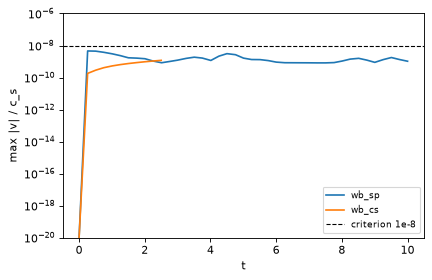

wb_sp 4.565063882209412e-09
PASS wb_sp   criterion {"max": {"vmax_over_cs": 1e-08}}
wb_cs 1.1812684960954636e-09
PASS wb_cs   criterion {"max": {"vmax_over_cs": 1e-08}}


In [3]:
fig, ax = plt.subplots(figsize=(5.5, 3.6))
for t in TESTS:
    h = os.path.join(WORK, t, 'run', 'rh.user.hst')
    ax.semilogy(nb.rt.hst_col(h, 'time'), np.maximum(nb.rt.hst_col(h, 'vcs_max'), 1e-20), '-', label=t)
ax.axhline(1e-8, c='k', ls='--', lw=1, label='criterion 1e-8')
ax.set(xlabel='t', ylabel='max |v| / c_s', ylim=(1e-20, 1e-6)); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
for t in TESTS:
    print(t, res[t]['vmax_over_cs']); nb.verdict(t, res[t])

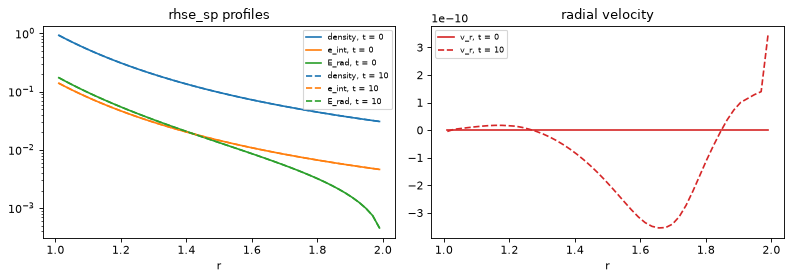

max relative change of the density over the run: 1.19e-08


In [4]:
# radial profiles of rhse_sp at t = 0 and at the end
m1t = nb.m1t
d = os.path.join(WORK, 'wb_sp_profiles')
if not vett.bins(d):
    os.makedirs(d, exist_ok=True)
    over = {'output2/file_type': 'bin', 'output2/bin_double': 'true', 'output2/variable': 'hydro_w',
            'output2/dt': 10.0, 'output3/file_type': 'bin', 'output3/bin_double': 'true',
            'output3/variable': 'vet', 'output3/dt': 10.0}
    vett.make_deck(os.path.join(nb.SUITE, 'decks', 'rhse_sp.athinput'), os.path.join(d, 'in.athinput'), over)
    rc, wall, _ = vett.run([EXE], d, ['-i', 'in.athinput'], threads=THREADS)
    print('return code', rc, '%.0f s' % wall)
r = vett.cell_centres(d)[0]
H, M = vett.bins(d, 'hydro_w'), vett.bins(d, 'vet')
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
for i, ls in ((0, '-'), (-1, '--')):
    h, m = vett.read_bin(H[i]), vett.read_bin(M[i])
    lab = 't = %g' % h['time']
    axs[0].semilogy(r, h['dens'][0].mean(0), ls, c='C0', label='density, ' + lab)
    axs[0].semilogy(r, h['eint'][0].mean(0), ls, c='C1', label='e_int, ' + lab)
    axs[0].semilogy(r, m['vet_e'][0].mean(0), ls, c='C2', label='E_rad, ' + lab)
    axs[1].plot(r, h['velx'][0].mean(0), ls, c='C3', label='v_r, ' + lab)
axs[0].set(xlabel='r', title='rhse_sp profiles'); axs[0].legend(fontsize=7)
axs[1].set(xlabel='r', title='radial velocity'); axs[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
h0, h1 = vett.read_bin(H[0]), vett.read_bin(H[-1])
print('max relative change of the density over the run: %.2e' % (abs(h1['dens']/h0['dens'] - 1).max()))